# State Transition Distance

For each generated transition $(s_t, s_{t+1})$, find the nearest encoder-decoder transition and report the squared distance:

$$d = \min_{(s_m, s_m') \in \text{enc-dec}} \|s - s_m\|^2 + \|s' - s_m'\|^2$$

where $s$ is the 67-dimensional joint angle vector (`qpos[7:]`, excluding root position and quaternion).

All features are z-normalized using encoder-decoder statistics before distance computation.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn.neighbors import NearestNeighbors

from scamper.analysis.discriminator.data_loading import (
    load_h5_dataset,
    list_h5_datasets,
    load_h5_metadata,
)

In [26]:
# ============ CONFIGURATION ============
DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"

REFERENCE_DATASET = "encoder_decoder_qpos"

# Joint angle indices in qpos (skip root pos 0:3 and root quat 3:7)
JOINT_ANGLE_START = 7

# Filtering threshold: transitions with d > threshold are considered invalid
DISTANCE_THRESHOLD = 40

# Datasets to exclude from evaluation
EXCLUDE_DATASETS = {"original_qpos"}

# Save path for plots
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
SAVE_NAME = "state_transition_distance"

In [27]:
# Discover datasets and load data
available = list_h5_datasets(DATASET_PATH)
metadata = load_h5_metadata(DATASET_PATH)

print("Available datasets:")
for name in available:
    print(f"  {name}")

# Auto-discover generated datasets (all *_qpos except the reference and excluded)
generated_names = [
    ds
    for ds in available
    if ds.endswith("_qpos") and ds != REFERENCE_DATASET and ds not in EXCLUDE_DATASETS
]
print(f"\nReference: {REFERENCE_DATASET}")
print(f"Excluded: {EXCLUDE_DATASETS}")
print(f"Generated datasets ({len(generated_names)}): {generated_names}")


def extract_transitions(qpos_data: np.ndarray) -> np.ndarray:
    """Extract consecutive joint-angle transition pairs from qpos data.

    Args:
        qpos_data: Shape (num_clips, num_steps, qpos_dim).

    Returns:
        Shape (num_clips * (num_steps - 1), 2 * num_joints) where each row
        is the concatenation [s_t, s_{t+1}] of joint angles.
    """
    joints = qpos_data[:, :, JOINT_ANGLE_START:]
    s_t = joints[:, :-1, :]
    s_tp1 = joints[:, 1:, :]
    n_clips, n_trans, dim = s_t.shape
    return np.concatenate(
        [s_t.reshape(-1, dim), s_tp1.reshape(-1, dim)], axis=1
    )


# Build transition vectors
ref_transitions = extract_transitions(load_h5_dataset(DATASET_PATH, REFERENCE_DATASET))
print(f"\nReference transitions: {ref_transitions.shape}")

gen_transitions = {}
for name in generated_names:
    gen_transitions[name] = extract_transitions(load_h5_dataset(DATASET_PATH, name))
    print(f"  {name}: {gen_transitions[name].shape}")

Available datasets:
  encoder_decoder_latents
  encoder_decoder_qpos
  original_qpos
  prior_deterministic_latents
  prior_deterministic_qpos
  prior_logvar_-0.5_latents
  prior_logvar_-0.5_qpos
  prior_logvar_-1_latents
  prior_logvar_-1_qpos
  prior_logvar_-2_latents
  prior_logvar_-2_qpos
  prior_logvar_-3_latents
  prior_logvar_-3_qpos
  prior_logvar_-4_latents
  prior_logvar_-4_qpos
  prior_logvar_0_latents
  prior_logvar_0_qpos
  prior_predicted_logvar_latents
  prior_predicted_logvar_qpos

Reference: encoder_decoder_qpos
Excluded: {'original_qpos'}
Generated datasets (8): ['prior_deterministic_qpos', 'prior_logvar_-0.5_qpos', 'prior_logvar_-1_qpos', 'prior_logvar_-2_qpos', 'prior_logvar_-3_qpos', 'prior_logvar_-4_qpos', 'prior_logvar_0_qpos', 'prior_predicted_logvar_qpos']

Reference transitions: (411738, 134)
  prior_deterministic_qpos: (411738, 134)
  prior_logvar_-0.5_qpos: (411738, 134)
  prior_logvar_-1_qpos: (411738, 134)
  prior_logvar_-2_qpos: (411738, 134)
  prior_logva

In [28]:
# Z-normalize using encoder-decoder statistics
ref_mean = ref_transitions.mean(axis=0)
ref_std = ref_transitions.std(axis=0)
ref_std = np.where(ref_std < 1e-8, 1.0, ref_std)

print(f"Normalization stats from {ref_transitions.shape[0]} reference transitions")
print(f"  Mean range: [{ref_mean.min():.4f}, {ref_mean.max():.4f}]")
print(f"  Std range:  [{ref_std.min():.6f}, {ref_std.max():.4f}]")

ref_norm = (ref_transitions - ref_mean) / ref_std
gen_norm = {name: (t - ref_mean) / ref_std for name, t in gen_transitions.items()}

Normalization stats from 411738 reference transitions
  Mean range: [-0.2633, 0.6946]
  Std range:  [0.000294, 0.4809]


In [ ]:
# Split-reference baseline: split enc-dec transitions in half,
# use one half as reference and query the other half.
split_rng = np.random.default_rng(42)
split_indices = split_rng.permutation(len(ref_norm))
mid = len(ref_norm) // 2
ref_half_a = ref_norm[split_indices[:mid]]
ref_half_b = ref_norm[split_indices[mid : 2 * mid]]

nn_baseline = NearestNeighbors(
    n_neighbors=1, algorithm="brute", metric="euclidean", n_jobs=-1
)
nn_baseline.fit(ref_half_a)
baseline_distances, _ = nn_baseline.kneighbors(ref_half_b)
baseline_sq = baseline_distances.ravel() ** 2

valid_mask = baseline_sq <= DISTANCE_THRESHOLD
baseline_filtered_pct = 100.0 * (1.0 - valid_mask.mean())
baseline_valid = baseline_sq[valid_mask]
baseline_mean = baseline_valid.mean() if len(baseline_valid) > 0 else float("nan")
baseline_std = baseline_valid.std() if len(baseline_valid) > 0 else float("nan")

print("Split-reference baseline (enc-dec vs itself):")
print(f"  mean(d) = {baseline_mean:.4f} +/- {baseline_std:.4f}, filtered = {baseline_filtered_pct:.2f}%")

# Build NN index on FULL normalized reference transitions for generation queries
nn_index = NearestNeighbors(
    n_neighbors=1, algorithm="brute", metric="euclidean", n_jobs=-1
)
nn_index.fit(ref_norm)
print(f"\nNN index: {ref_norm.shape[0]} reference transitions, {ref_norm.shape[1]} dims")
print(f"Distance threshold: {DISTANCE_THRESHOLD}")

# Query each generated dataset
results = {}
for name in generated_names:
    distances, _ = nn_index.kneighbors(gen_norm[name])
    sq_dist = distances.ravel() ** 2  # squared Euclidean

    # Filter: transitions with d > threshold are invalid
    valid_mask = sq_dist <= DISTANCE_THRESHOLD
    filtered_pct = 100.0 * (1.0 - valid_mask.mean())
    valid_dist = sq_dist[valid_mask]

    mean_d = valid_dist.mean() if len(valid_dist) > 0 else float("nan")
    std_d = valid_dist.std() if len(valid_dist) > 0 else float("nan")

    results[name] = {
        "mean": mean_d,
        "std": std_d,
        "filtered_pct": filtered_pct,
        "distances": sq_dist,
    }
    print(f"{name}: mean(d) = {mean_d:.4f} +/- {std_d:.4f}, filtered = {filtered_pct:.2f}%")

In [ ]:
# Label map: dataset name -> sampling noise sigma (matches plot_kid_results.ipynb)
label_map = {
    "prior_deterministic_qpos": "0.00",
    "prior_logvar_-4_qpos": "0.14",
    "prior_logvar_-3_qpos": "0.22",
    "prior_logvar_-2_qpos": "0.37",
    "prior_logvar_-1_qpos": "0.61",
    "prior_logvar_-0.5_qpos": "0.78",
    "prior_logvar_0_qpos": "1.00",
    "prior_predicted_logvar_qpos": "predicted",
}

# Filter to datasets that have a label and are in results
plot_names = [n for n in label_map if n in results]
# Sort: numeric labels ascending, then non-numeric at end
def sort_key(name):
    lbl = label_map[name]
    try:
        return (0, float(lbl))
    except ValueError:
        return (1, lbl)

plot_names.sort(key=sort_key)

# Summary table (include baseline)
rows = [{"sigma": "baseline", "Distance (d)": f"{baseline_mean:.3f} ({baseline_std:.3f})", "Filtered (%)": f"{baseline_filtered_pct:.2f}"}]
for name in plot_names:
    r = results[name]
    rows.append({
        "sigma": label_map[name],
        "Distance (d)": f"{r['mean']:.3f} ({r['std']:.3f})",
        "Filtered (%)": f"{r['filtered_pct']:.2f}",
    })
summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

# --- Bar plots ---
labels = [label_map[n] for n in plot_names]
means = [results[n]["mean"] for n in plot_names]
stds = [results[n]["std"] for n in plot_names]
filtered_pcts = [results[n]["filtered_pct"] for n in plot_names]

bar_rgb = (0, 170, 188)
bar_color = tuple(c / 255 for c in bar_rgb)

fig, axes = plt.subplots(1, 2, figsize=(16, max(3, len(labels) * 0.5 + 1)))

# Left: Distance
ax = axes[0]
sns.barplot(y=labels, x=means, color=bar_color, edgecolor=bar_color, ax=ax)
bar_positions = sorted(
    [patch.get_y() + patch.get_height() / 2 for patch in ax.patches]
)
ax.errorbar(
    means, bar_positions, xerr=stds,
    fmt="none", ecolor="black", capsize=4, capthick=2, linewidth=2,
)
# Baseline reference line
ax.axvline(baseline_mean, color="red", linestyle="--", alpha=0.7, label=f"split baseline ({baseline_mean:.3f})")
x_max = max(m + s for m, s in zip(means, stds))
ax.set_xlim(0, x_max * 1.1)
ax.set_xlabel("Distance (d)", fontsize=20, labelpad=12)
ax.set_ylabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=12)
sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# Right: Filtered %
ax = axes[1]
sns.barplot(y=labels, x=filtered_pcts, color=bar_color, edgecolor=bar_color, ax=ax)
ax.axvline(baseline_filtered_pct, color="red", linestyle="--", alpha=0.7, label=f"split baseline ({baseline_filtered_pct:.2f}%)")
ax.set_xlabel("Filtered (%)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=12)
sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{fmt}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / SAVE_NAME}")
plt.show()

In [ ]:
# Distance distributions (histograms)
fig, ax = plt.subplots(figsize=(10, 6))

for name in plot_names:
    lbl = label_map[name]
    d = results[name]["distances"]
    ax.hist(
        d, bins=100, alpha=0.4, density=True,
        label=f"$\\sigma$={lbl} (mean={results[name]['mean']:.2f})",
    )

ax.axvline(DISTANCE_THRESHOLD, color="red", linestyle="--", alpha=0.7, label=f"threshold={DISTANCE_THRESHOLD}")
ax.set_xlabel("Squared Transition Distance", fontsize=16)
ax.set_ylabel("Density", fontsize=16)
ax.legend(fontsize=10, loc="upper right")
ax.tick_params(labelsize=14)
ax.grid(True, alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

# Joint Autocorrelation Analysis

Compare temporal coherence of joint angle trajectories across datasets. For each joint, compute the autocorrelation function averaged across clips, then summarize with the autocorrelation time (lag at which autocorrelation drops below 1/e).

In [29]:
# Load raw qpos for autocorrelation (need full time series, not transitions)
available = list_h5_datasets(DATASET_PATH)
ac_generated_names = [
    ds for ds in available
    if ds.endswith("_qpos")
    and ds != REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]

ac_label_map = {
    "encoder_decoder_qpos": "Imitation Rollout",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
}

ac_datasets = [REFERENCE_DATASET] + ac_generated_names

ac_qpos = {}
for name in ac_datasets:
    data = load_h5_dataset(DATASET_PATH, name)
    ac_qpos[name] = data[:, :, JOINT_ANGLE_START:]  # (num_clips, num_steps, 67)
    print(f"  {name}: {ac_qpos[name].shape}")

  encoder_decoder_qpos: (842, 490, 67)
  prior_deterministic_qpos: (842, 490, 67)
  prior_logvar_-0.5_qpos: (842, 490, 67)
  prior_logvar_-1_qpos: (842, 490, 67)
  prior_logvar_-2_qpos: (842, 490, 67)
  prior_logvar_-3_qpos: (842, 490, 67)
  prior_logvar_-4_qpos: (842, 490, 67)
  prior_logvar_0_qpos: (842, 490, 67)


In [30]:
def compute_autocorrelation_per_clip(joints: np.ndarray, max_lag: int) -> np.ndarray:
    """Compute autocorrelation per clip (averaged across joints).

    Args:
        joints: Shape (num_clips, num_steps, num_joints).
        max_lag: Maximum lag to compute.

    Returns:
        Per-clip autocorrelation curves of shape (num_clips, max_lag + 1).
    """
    num_clips, num_steps, num_joints = joints.shape
    max_lag = min(max_lag, num_steps - 1)

    centered = joints - joints.mean(axis=1, keepdims=True)
    var = np.sum(centered ** 2, axis=1) / num_steps  # (num_clips, num_joints)

    ac_curves = np.zeros((num_clips, num_joints, max_lag + 1))
    for lag in range(max_lag + 1):
        if lag == 0:
            ac_curves[:, :, lag] = 1.0
        else:
            cov = np.sum(centered[:, :num_steps - lag, :] * centered[:, lag:, :], axis=1) / (num_steps - lag)
            ac_curves[:, :, lag] = np.where(var > 1e-12, cov / var, 0.0)

    # Average across joints, keep per-clip: (num_clips, max_lag + 1)
    return ac_curves.mean(axis=1)


def autocorrelation_time(ac_curve: np.ndarray, threshold: float = 1.0 / np.e) -> float:
    """Find the lag at which autocorrelation drops below threshold."""
    below = np.where(ac_curve < threshold)[0]
    return int(below[0]) if len(below) > 0 else len(ac_curve) - 1


MAX_LAG = 200

# Compute per-clip autocorrelation, then mean/std across clips
ac_stats = {}  # name -> {"mean": ..., "std": ...}
ac_times = {}

for name in ac_datasets:
    per_clip = compute_autocorrelation_per_clip(ac_qpos[name], MAX_LAG)
    mean_curve = per_clip.mean(axis=0)
    std_curve = per_clip.std(axis=0)

    ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    ac_times[name] = autocorrelation_time(mean_curve)

    label = ac_label_map.get(name, name)
    print(f"{label}: autocorrelation time = {ac_times[name]} steps")

Imitation Rollout: autocorrelation time = 58 steps
$\sigma$=0.00: autocorrelation time = 54 steps
$\sigma$=0.78: autocorrelation time = 47 steps
$\sigma$=0.61: autocorrelation time = 49 steps
$\sigma$=0.37: autocorrelation time = 51 steps
$\sigma$=0.22: autocorrelation time = 53 steps
$\sigma$=0.14: autocorrelation time = 54 steps
$\sigma$=1.00: autocorrelation time = 44 steps


/tmp/ipykernel_1371226/2328482006.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", n_gen)


Saved autocorrelation curves


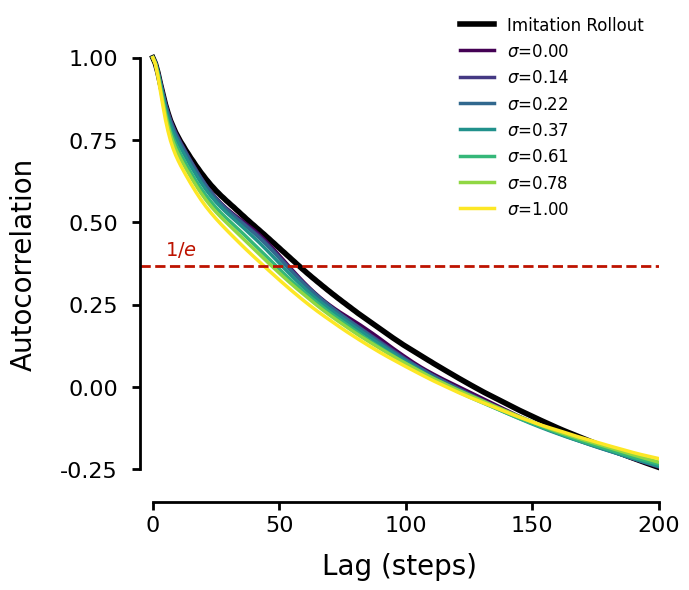

In [59]:
# Color palette: Imitation Rollout in black, generated in a colormap
import matplotlib.cm as cm

n_gen = len(ac_generated_names)
cmap = cm.get_cmap("viridis", n_gen)

# Sort generated names by sigma value
def ac_sort_key(name):
    lbl = ac_label_map.get(name, "")
    val = lbl.replace("$\\sigma$=", "")
    try:
        return float(val)
    except ValueError:
        return 999.0

ac_gen_sorted = sorted(ac_generated_names, key=ac_sort_key)

# Assign colors
ac_colors = {REFERENCE_DATASET: "black"}
for i, name in enumerate(ac_gen_sorted):
    ac_colors[name] = cmap(i)

# Plot order: enc-dec first, then sorted generated
ac_plot_order = [REFERENCE_DATASET] + ac_gen_sorted

lags = np.arange(MAX_LAG + 1)
red_color = tuple(c / 255 for c in (189, 19, 0))

fig, ax = plt.subplots(figsize=(7, 6))

for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    mean = ac_stats[name]["mean"]
    color = ac_colors[name]
    lw = 4 if name == REFERENCE_DATASET else 2.5

    ax.plot(lags, mean, linewidth=lw, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

# Set y ticks
base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

# Trim spines to tick range — they won't meet since x starts at 0 but y starts at -0.25
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# 1/e threshold line with label sitting above it
ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_curves.{fmt}", bbox_inches="tight", dpi=150)
print(f"Saved autocorrelation curves")
plt.show()

In [32]:
# Min autocorrelation (mean curve) for each dataset
for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    min_val = ac_stats[name]["mean"].min()
    min_lag = ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

   Imitation Rollout: min autocorrelation = -0.2443 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.2433 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.2401 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.2422 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.2407 at lag 200
       $\sigma$=0.61: min autocorrelation = -0.2344 at lag 200
       $\sigma$=0.78: min autocorrelation = -0.2285 at lag 200
       $\sigma$=1.00: min autocorrelation = -0.2177 at lag 200


/tmp/ipykernel_1371226/2029120849.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=ac_labels, x=ac_values, palette=colors, edgecolor=colors, ax=ax)


Saved autocorrelation time bar plot


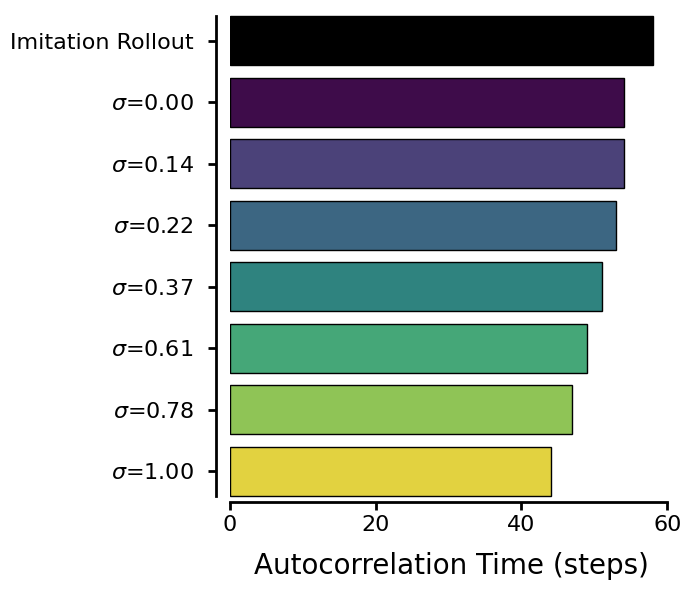

In [33]:
# Bar plot of autocorrelation times
ac_bar_order = [REFERENCE_DATASET] + ac_gen_sorted
ac_bar_order = [n for n in ac_bar_order if n in ac_times]

ac_labels = [ac_label_map.get(n, n) for n in ac_bar_order]
ac_values = [ac_times[n] for n in ac_bar_order]
colors = [ac_colors[n] for n in ac_bar_order]

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(y=ac_labels, x=ac_values, palette=colors, edgecolor=colors, ax=ax)

ax.set_xlabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

bar_positions = sorted([p.get_y() for p in ax.patches])
ax.spines["left"].set_bounds(bar_positions[0], bar_positions[-1] + ax.patches[0].get_height())

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_time.{fmt}", bbox_inches="tight")
print(f"Saved autocorrelation time bar plot")
plt.show()